# AP 155 Lab Exercise
---
## Exercise 5: Matrices

_Instructions_: 
- **Report figure:** (See step 5 of the problem)
- **Report discussion:** Explain the pattern shown in the report figure. 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.linalg import *

### Problem 1: (Circuit Analysis)


Consider a long chain of resistors wired up like this:

<img src="reschain.png" alt="Alt text" width=95%>

All the resistors have the same resistance~$R$.  The power rail at the top is at voltage~$V_+=5$V.  The problem is to find the voltages $V_1...V_N$ at the internal points in the circuit.

1. **Using Ohm's law and the Kirchhoff current law**, which says that the total net current flow out of (or into) any junction in a circuit must be zero, show that the voltages $V_1\ldots V_N$ satisfy the equations

$$3V_1 - V_2 - V_3 = V_+ $$
$$-V_1 + 4V_2 - V_3 - V_4 = V_+ $$
      
$$-V_{i-2} - V_{i-1} + 4V_i - V_{i+1} - V_{i+2} = 0 $$

$$-V_{N-3} - V_{N-2} + 4V_{N-1} - V_N = V_- = 0 $$
$$-V_{N-2} - V_{N-1} + 3V_N = V_- = 0 $$

Note: The assignment of $V_-$ is to make the equations symmetric

2. Express these equations in vector form~$A\vec{v} = \vec{w}$ and find the values of the matrix~$A$ and the vector~$\vec{w}$.

3. Write a program to solve for the values of the~$V_i$ when there are $N=6$ internal junctions with unknown voltages.  (Hint: All the values of $V_i$ should lie between zero and $5$V.  If they don't, something is wrong.)

4. Now repeat your calculation for the case where there are $N=10\,000$ internal junctions.  This part is not possible using standard tools like the *solve* function.  You need to make use of the fact that the matrix~$\vec{A}$ is banded.

5. [Report Figure] Try different values of $N \in \{10, 50, 100, 500, 1000, 5000, 10000\}$. For each N, plot the junction voltage. Overlay all the curves on a single plot. What pattern do you see? Why?

In [2]:
def createBandedMatrix(shape, repeatingUnit, start, step):
    '''
    Creates a banded square matrix given the list of the repeating unit, the starting index\
    of the repeating unit in the top row, and the step of the starting index for the next row
    '''

    bandedMat = np.zeros(shape)
    rowInput = np.zeros(shape[1])
    rowInput[start:start+len(repeatingUnit)] = repeatingUnit
    for i in range(bandedMat.shape[0]):
        bandedMat[i] = rowInput
        rowInput = np.roll(rowInput, step)

    return bandedMat
    


def createJuncMatrixTriUni(N, Vplus, Vminus):
    '''
    Creates a matrix relating the current through the different junctions given a uniform,\
    triangular resistance network.\
    V_1 corresponds to index 0 in this matrix; V_2 --> index 1, etc. 
    '''

    matA = np.zeros((N,N))

    #Need to make this portion not hard coded
    matA[2:-2] = createBandedMatrix((N-4, N), [-1,-1,4,-1,-1], 0, 1)
    matA[0,0:3] = [3,-1,-1]
    matA[1,0:4] = [-1,4,-1,-1]
    matA[-2,-4:] = matA[1,0:4][::-1]
    matA[-1,-3:] = matA[0,0:3][::-1]
    
    vecW = np.zeros(N)
    vecW[0], vecW[1], vecW[-2], vecW[-1] = Vplus, Vplus, Vminus, Vminus

    return matA, vecW
    
    

In [3]:
#for N = 6
matA, vecW = createJuncMatrixTriUni(6,5,0)
display(matA)
display(vecW)
voltages = np.linalg.solve(matA, vecW)
voltages

array([[ 3., -1., -1.,  0.,  0.,  0.],
       [-1.,  4., -1., -1.,  0.,  0.],
       [-1., -1.,  4., -1., -1.,  0.],
       [ 0., -1., -1.,  4., -1., -1.],
       [ 0.,  0., -1., -1.,  4., -1.],
       [ 0.,  0.,  0., -1., -1.,  3.]])

array([5., 5., 0., 0., 0., 0.])

array([3.7254902 , 3.43137255, 2.74509804, 2.25490196, 1.56862745,
       1.2745098 ])

In [4]:
#for N = 10_000
matA, vecW = createJuncMatrixTriUni(10_000,5,0)
#voltages = np.linalg.solve(matA, vecW) --> works, needs some time

#using LU decomposition: 
# lu_and_piv = lu_factor(matA)
# voltages = lu_solve(lu_and_piv, vecW)
#voltages

#using inverse
matA_inv = np.linalg.inv(matA)
voltages = matA_inv @ vecW
voltages

array([4.99888228e+00, 4.99861842e+00, 4.99802841e+00, ...,
       1.97158611e-03, 1.38158071e-03, 1.11772227e-03])

In [5]:
#for multiple N

N = [5, 10, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
Vplus = 5
Vminus = 0

voltage_curves = dict()


for n in N:
    matA, vecW = createJuncMatrixTriUni(n,Vplus,Vminus)
    # voltage_curves[n] = np.linalg.solve(matA, vecW)
    lu_and_piv = lu_factor(matA)
    voltage_curves[n] = lu_solve(lu_and_piv, vecW)
    

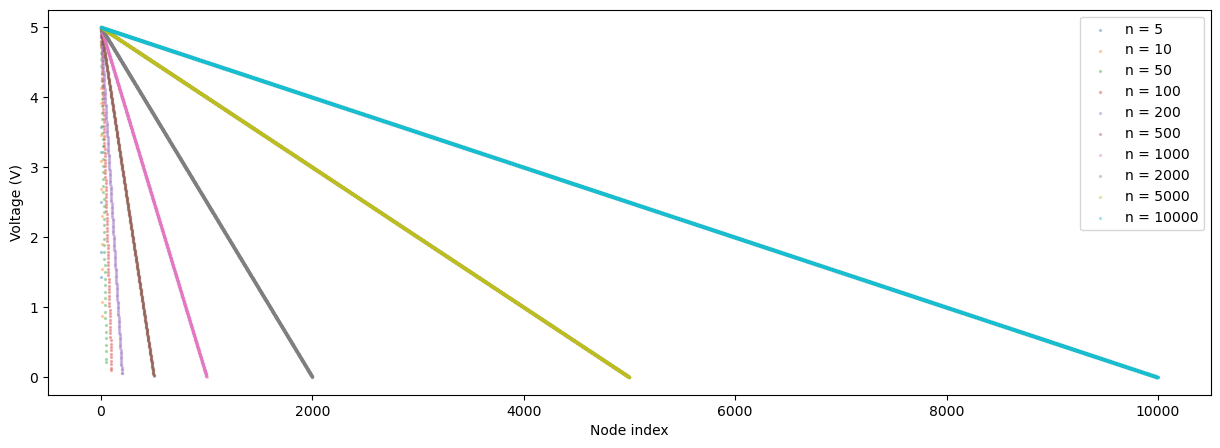

In [6]:
#Plotting
fig, ax = plt.subplots(figsize = (15,5))
for n in N:
    ax.scatter(np.arange(n), voltage_curves[n], label = f'n = {n}', s = 2, alpha = 0.3)
ax.set_xlabel('Node index')
ax.set_ylabel('Voltage (V)')
# ax.set_xscale('log')
# ax.set_yscale('log')
ax.legend()
fig.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

## Section 3 (Notes)

### Some codes for solving matrix problems

* solving matrix equations ($\bf{A}\vec{x} = \vec{b}$) -> `np.linalg.solve`
* LU-decomposition ($\bf{A} = \bf{L}\bf{U}$) -> `scipy.linalg.lu`
* matrix inversion ($\bf{A}^{-1}$) -> `np.linalg.inv`
* QR-decomposition ($\bf{A} = \bf{Q}\bf{R}$) -> `scipy.linalg.qr`
* eigenvalue problem ($\bf{A}\vec{x} = \lambda \vec{x}$) -> `np.linalg.eig`

Solving matrix problems by themselves isn't difficult. There is an abundance of linear algebra libraries that are ready to use: from the battle-tested ones (the classic [BLAS](https://www.netlib.org/blas/) and [LAPACK](https://www.netlib.org/lapack/)), HPC tools for large problems ([ScaLAPACK](https://netlib.org/scalapack/)), to hardware-accelerated ones often with GPUs ([cuBLAS](https://docs.nvidia.com/cuda/cublas/index.html) and [cuSolver](https://docs.nvidia.com/cuda/cusolver/index.html) for NVIDIA). 

The hardest part is actually composing the matrix. How do you transform a physical problem into a linear algebra problem?

* Circuit: https://personal.math.vt.edu/embree/cmda3606/chapter2.pdf
* Embree [main notes](https://personal.math.vt.edu/embree/cmda3606notes.pdf) + [lab manual](https://personal.math.vt.edu/embree/labman.pdf)

#### Sample Usage

In [7]:
A = np.array([[1,0,2],[-2,-1,3],[0,3,5]])
B = np.array([[-2],[1],[-3]])


# Known: A@B == C

In [8]:
sigma_z = [[1,0],[0,-1]]
sigma_y = [[0,-1j],[1j,0]]
sigma_x = [[0,1],[1,0]]

In [9]:
ans = np.linalg.solve(sigma_x, sigma_y) # sigma_x @ ___ = sigma_y
ans = np.linalg.inv(A) @ B


In [10]:
from scipy.linalg import *
p, l, u = lu(A)
p, l, u

(array([[0., 0., 1.],
        [1., 0., 0.],
        [0., 1., 0.]]),
 array([[ 1.        ,  0.        ,  0.        ],
        [-0.        ,  1.        ,  0.        ],
        [-0.5       , -0.16666667,  1.        ]]),
 array([[-2.        , -1.        ,  3.        ],
        [ 0.        ,  3.        ,  5.        ],
        [ 0.        ,  0.        ,  4.33333333]]))

### Sample Problem

Suppose you have a hanging mass M supported by two ropes (angled by $\alpha$ and $\beta$ with respect to the ceiling). Make a function that calculates the tension on each of the ropes. 


Newton's Laws Equation:
$$T_A\sin(\alpha) + T_B\sin(\beta) = Mg $$
$$T_A\cos(\alpha) - T_B\cos(\beta) = 0 $$


In [11]:
alpha = np.pi/6
beta = np.pi/3
M = 100/9.81
g = 9.81

A = np.array([
    [np.sin(alpha), np.sin(beta)],
    [np.cos(alpha), -np.cos(beta)]
])
w = [M*g, 0]

np.linalg.solve(A,w)

array([50.        , 86.60254038])

### np.roll

In [12]:
## Useful tips. Not required to solve the problems below!

# Suppose you have a Numpy array
x = np.zeros((4,4))
for row in x:
    print(row)

#rint(x[0,1:3])


# I can move all values to the left/right using roll
x_roll = np.roll(x, 1) # change 1 to -1, what happens? 
#x_roll2 = np.roll(x, -1)
print(x_roll)



[0. 0. 0. 0.]
[0. 0. 0. 0.]
[0. 0. 0. 0.]
[0. 0. 0. 0.]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### Example of an Undetermined System

Masses $m_1, m_2, m_3$, and $m_4$ lie on a $2.00$ [m] beam of negligible mass. They are located $0.20, 0.70, 1.10$, and $1.40$ [m] away from the left end of the beam. Determine the masses $m_1, m_2, m_3$, and $m_4$, given the following constraints: 

- The total mass is $8.00$ [kg]
- If a pivot is placed halfway, the beam will balance if a $1.05$ [kg] mass is placed on the right-end of the beam
- If a pivot is placed $1.20$ [m] away from the right end, then the beam would balance if a $0.550$ [N m] torque were applied on the left end of the beam.
- If the system is split midway, the total mass on the left is $1.00$ [kg] heavier than the total mass on the right


In [13]:
#The matrix A and vector b (in Ax = b) would be:
b = [8, 1.05, -0.550, 1.00]
A = np.array([
    [1,1,1,1],
    [0.8,0.3,-0.1,-0.4],
    [0.6,0.1,-0.3,-0.6],
    [1,1,-1,-1]
])

In [14]:
np.linalg.matrix_rank(A), np.shape(A)[0]


(3, 4)

The rank is less than the number of rows
This is because in matrix A, the third row is a linear combination of the first two rows $(A_3 = A_2 - 0.2(A_1))$. Hence, this is an undetermined system (or could be an impossible system if the 2nd and 3rd condition cannot be satisfied at the same time).

What if we changed the problem: Suppose the 3rd condition (3rd bullet point) is changed to:

- *The mass of $m_1$ is $1.00 [kg]$*

In [15]:
Anew = A.copy()
bnew = b.copy()
Anew[2], bnew[2] = [1,0,0,0], 1

In [17]:
np.linalg.solve(Anew,bnew)

array([1. , 3.5, 2. , 1.5])